# M2 — Leaf Disease Detection with Grad-CAM

**Smart Crop Advisory System** · Problem Statement **SIH25010** (Smart India Hackathon 2025)

B.Tech Project, Semester VII · Department of Artificial Intelligence & Machine Learning, SIT Pune

**Module owner:** Miraat Gupta (23070126073) · *Deep Learning / Computer Vision core*

---

### What this notebook does

| Step | Description |
|------|-------------|
| 1 | Load a leaf-disease image dataset (folder-per-class layout) |
| 2 | Train a CNN using transfer learning on a MobileNetV2 backbone |
| 3 | Evaluate — accuracy, per-class report, confusion matrix |
| 4 | Implement **Grad-CAM** to show *which* leaf region drove each prediction |
| 5 | Launch a **Gradio** app and obtain the public `.gradio.live` link for the HTML hub |

### Datasets (add one in Kaggle, or download in Colab)
- [PlantVillage — 54,305 images, 38 classes](https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset)
- [New Plant Diseases Dataset — augmented ~87k](https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset)

### How to run
1. **First run:** keep `MAX_CLASSES = 10` in the config cell — trains in a few minutes and proves the pipeline works.
2. **Final model:** set `MAX_CLASSES = None`, restart, and Run All.
3. **Later sessions:** set `RUN_MODE = "app"` to skip training and just relaunch the link.

## 1. Environment setup

Gradio is not pre-installed on Kaggle/Colab, so install it first. Restart the runtime if prompted.

In [1]:
# Run once per session
!pip install -q gradio

In [2]:
import os
import json
import glob
import datetime

import numpy as np
import matplotlib
import matplotlib.cm as cm
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import MobileNetV2

from PIL import Image

print(f"TensorFlow : {tf.__version__}")
gpus = tf.config.list_physical_devices("GPU")
print(f"GPU        : {gpus[0].name if gpus else 'NOT AVAILABLE — training will be slow'}")
print(f"Started    : {datetime.datetime.now():%Y-%m-%d %H:%M:%S}")

TensorFlow : 2.20.0
GPU        : /physical_device:GPU:0
Started    : 2026-07-29 07:31:32


## 2. Configuration

**This is the only cell you normally need to edit.**

`MAX_CLASSES` controls how many disease classes are used. Start small to verify the
pipeline end-to-end, then set it to `None` for the full model used in the report.

In [3]:
RUN_MODE = "train"          # "train" = train then launch app | "app" = load saved model and launch only

IMG_SIZE   = 224            # MobileNetV2 native input size
BATCH_SIZE = 32
SEED       = 42

EPOCHS_HEAD     = 5         # phase 1 — frozen backbone
EPOCHS_FINETUNE = 5         # phase 2 — fine-tuning
FINE_TUNE_FROM  = 100       # unfreeze backbone layers from this index onward

LR_HEAD     = 1e-3
LR_FINETUNE = 1e-5          # must be small, or pretrained features are destroyed

VALIDATION_SPLIT = 0.2

# None = use every class. Set to e.g. 10 for a fast first run.
MAX_CLASSES = 10

OUTPUT_DIR   = "m2_outputs"
WEIGHTS_PATH = os.path.join(OUTPUT_DIR, "m2_leaf_disease.weights.h5")
CLASSES_PATH = os.path.join(OUTPUT_DIR, "class_names.json")

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Configuration loaded.")

Configuration loaded.


## 3. Locate the dataset

The first path that exists and contains class sub-folders is used. If your data sits
elsewhere, add its path to the top of `CANDIDATE_DIRS`.

In [5]:
# --- Download PlantVillage into Colab ---
!pip install -q kaggle

from google.colab import files
print("Upload your kaggle.json")
files.upload()          # a "Choose Files" button appears — pick kaggle.json

!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p /content --unzip

# Locate the 'color' folder wherever it landed
import os
for root, dirs, _ in os.walk("/content"):
    if os.path.basename(root) == "color" and len(dirs) > 10:
        print("FOUND:", root)
        break

Upload your kaggle.json


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [01:36<00:00, 22.6MB/s]

FOUND: /content/plantvillage dataset/color


In [7]:
CANDIDATE_DIRS = [
    "/content/plantvillage dataset/color",
    "/kaggle/input/plantvillage-dataset/plantvillage dataset/color",
    "/kaggle/input/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train",
    "./data/color",
]


def find_data_dir():
    """Return the first candidate directory that exists and has class sub-folders."""
    for path in CANDIDATE_DIRS:
        if os.path.isdir(path):
            subdirs = [d for d in glob.glob(os.path.join(path, "*")) if os.path.isdir(d)]
            if subdirs:
                print(f"Using dataset directory : {path}")
                print(f"Class folders found     : {len(subdirs)}")
                return path
    raise FileNotFoundError(
        "No dataset directory found.\n"
        "Add the PlantVillage dataset in Kaggle, or edit CANDIDATE_DIRS above."
    )


if RUN_MODE == "train":
    DATA_DIR = find_data_dir()

Using dataset directory : /content/plantvillage dataset/color
Class folders found     : 38


## 4. Data pipeline

Images are loaded straight from the folder structure, split 80/20 into train/validation,
cached and prefetched so the GPU is not waiting on disk.

In [8]:
def build_datasets(data_dir):
    """Create training and validation tf.data pipelines from a folder-per-class dataset."""
    common = dict(
        validation_split=VALIDATION_SPLIT,
        seed=SEED,
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        label_mode="int",
    )

    train_ds = tf.keras.utils.image_dataset_from_directory(data_dir, subset="training", **common)
    val_ds   = tf.keras.utils.image_dataset_from_directory(data_dir, subset="validation", **common)

    class_names = train_ds.class_names

    # Optionally keep only the first MAX_CLASSES classes (faster prototyping runs)
    if MAX_CLASSES is not None and MAX_CLASSES < len(class_names):
        keep = MAX_CLASSES
        class_names = class_names[:keep]
        keep_t = tf.constant(keep, dtype=tf.int64)

        def _filter(x, y):
            return tf.less(tf.cast(y, tf.int64), keep_t)

        train_ds = train_ds.unbatch().filter(_filter).batch(BATCH_SIZE)
        val_ds   = val_ds.unbatch().filter(_filter).batch(BATCH_SIZE)
        print(f"Restricted to first {keep} classes for this run")

    print(f"Number of classes : {len(class_names)}")

    autotune = tf.data.AUTOTUNE
    train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(autotune)
    val_ds   = val_ds.cache().prefetch(autotune)

    return train_ds, val_ds, class_names


if RUN_MODE == "train":
    train_ds, val_ds, class_names = build_datasets(DATA_DIR)
    with open(CLASSES_PATH, "w") as f:
        json.dump(class_names, f, indent=2)

Found 54305 files belonging to 38 classes.
Using 43444 files for training.
Found 54305 files belonging to 38 classes.
Using 10861 files for validation.
Restricted to first 10 classes for this run
Number of classes : 10


### 4.1 Inspect a batch

Always look at the data before training — it catches mislabelled folders and colour-channel
problems immediately.

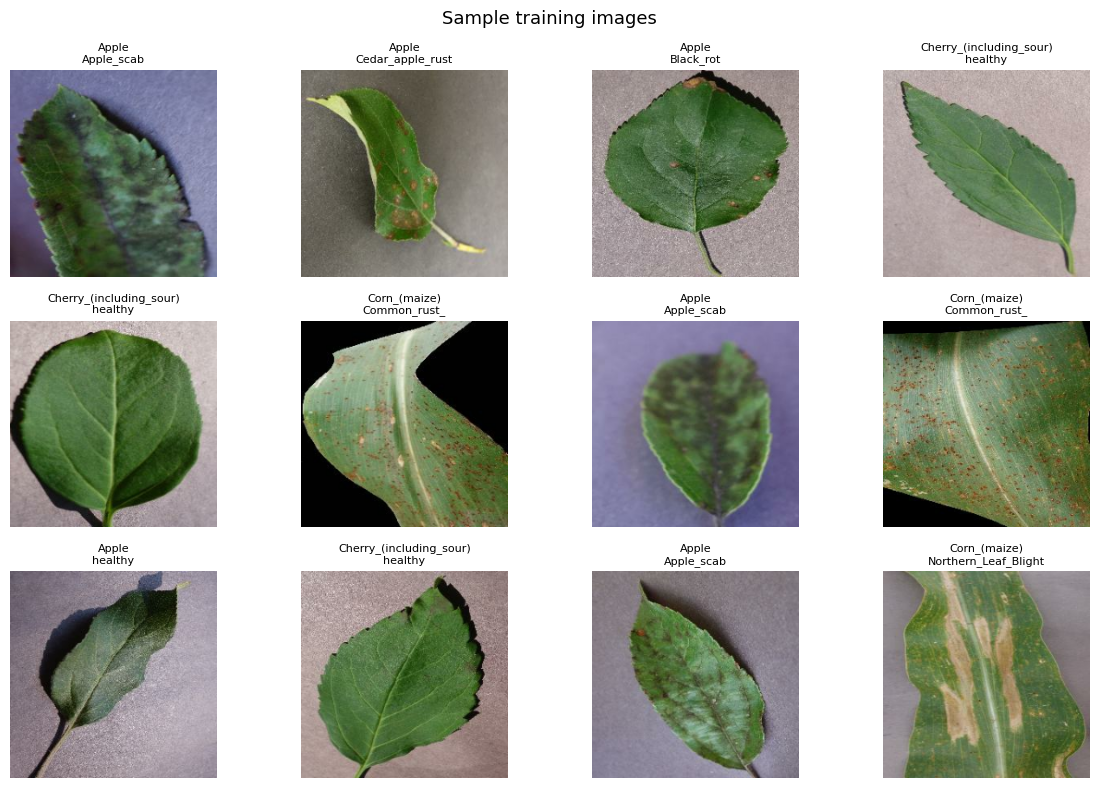

In [9]:
if RUN_MODE == "train":
    plt.figure(figsize=(12, 8))
    for images, labels in train_ds.take(1):
        for i in range(min(12, images.shape[0])):
            ax = plt.subplot(3, 4, i + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(class_names[labels[i]].replace("___", "\n")[:38], fontsize=8)
            plt.axis("off")
    plt.suptitle("Sample training images", fontsize=13)
    plt.tight_layout()
    plt.show()

## 5. Model architecture

Augmentation is applied only during training (Keras handles this automatically).

In [10]:
data_augmentation = models.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.15),
        layers.RandomZoom(0.15),
        layers.RandomContrast(0.10),
    ],
    name="augmentation",
)

### 5.1 Building the network

Two models are built that **share the same layers**:

- `model` — inputs → class probabilities (used for training and inference)
- `gradcam` — inputs → *(backbone feature map, probabilities)* (used for Grad-CAM)

This matters. The usual Grad-CAM failure is that the backbone is a *nested* model, so its
convolutional output cannot be reached from the outer graph. By capturing the `feature_map`
tensor at build time we avoid that entirely — and because both models reuse the same layer
objects, loading weights into `model` automatically updates `gradcam`.

Preprocessing (`Rescaling` to [-1, 1]) sits **inside** the model, so the Gradio app can feed
raw 0–255 pixels and can never drift out of sync with training.

In [11]:
def build_model(num_classes):
    """Return (model, gradcam_model, backbone). All three share the same layer objects."""
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")

    x = data_augmentation(inputs)

    # MobileNetV2 expects inputs scaled to [-1, 1]
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="preprocess")(x)

    backbone = MobileNetV2(
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
    )
    backbone._name = "backbone"
    backbone.trainable = False

    # With include_top=False the backbone output IS the final conv activation
    # ('out_relu', 7x7x1280) — exactly the tensor Grad-CAM needs.
    feature_map = backbone(x, training=False)

    p = layers.GlobalAveragePooling2D(name="gap")(feature_map)
    p = layers.Dropout(0.3, name="dropout")(p)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(p)

    model   = models.Model(inputs, outputs, name="m2_leaf_disease")
    gradcam = models.Model(inputs, [feature_map, outputs], name="m2_gradcam")

    return model, gradcam, backbone

In [12]:
if RUN_MODE == "train":
    model, gradcam_model, backbone = build_model(len(class_names))
    model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "m2_leaf_disease"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Rescaling)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Training — two-phase transfer learning

**Phase 1** trains only the classifier head on top of frozen ImageNet features.
**Phase 2** unfreezes the top of the backbone and fine-tunes at a much lower learning rate.

Note that BatchNormalization layers stay frozen throughout. Unfreezing them destabilises
fine-tuning on modest datasets — a common and silent accuracy killer.

In [13]:
def train(model, backbone, train_ds, val_ds):
    cb = [
        callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    ]

    print("=" * 70)
    print("PHASE 1  |  Training classifier head (backbone frozen)")
    print("=" * 70)

    model.compile(
        optimizer=optimizers.Adam(learning_rate=LR_HEAD),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    hist1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=cb)

    print("\n" + "=" * 70)
    print("PHASE 2  |  Fine-tuning top layers of the backbone")
    print("=" * 70)

    backbone.trainable = True
    for layer in backbone.layers[:FINE_TUNE_FROM]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    trainable = sum(1 for l in backbone.layers if l.trainable)
    print(f"Trainable backbone layers: {trainable} / {len(backbone.layers)}")

    model.compile(
        optimizer=optimizers.Adam(learning_rate=LR_FINETUNE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE, callbacks=cb)

    return hist1, hist2

In [14]:
if RUN_MODE == "train":
    hist1, hist2 = train(model, backbone, train_ds, val_ds)
    model.save_weights(WEIGHTS_PATH)
    print(f"\nWeights saved -> {WEIGHTS_PATH}")

PHASE 1  |  Training classifier head (backbone frozen)
Epoch 1/5
    232/Unknown 23s 57ms/step - accuracy: 0.6709 - loss: 1.0647

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


232/232 ━━━━━━━━━━━━━━━━━━━━ 40s 130ms/step - accuracy: 0.8211 - loss: 0.5821 - val_accuracy: 0.9419 - val_loss: 0.2161 - learning_rate: 0.0010
Epoch 2/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 16s 69ms/step - accuracy: 0.9375 - loss: 0.1959 - val_accuracy: 0.9543 - val_loss: 0.1553 - learning_rate: 0.0010
Epoch 3/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.9441 - loss: 0.1588 - val_accuracy: 0.9494 - val_loss: 0.1435 - learning_rate: 0.0010
Epoch 4/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.9489 - loss: 0.1465 - val_accuracy: 0.9666 - val_loss: 0.1107 - learning_rate: 0.0010
Epoch 5/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.9572 - loss: 0.1235 - val_accuracy: 0.9682 - val_loss: 0.1072 - learning_rate: 0.0010

PHASE 2  |  Fine-tuning top layers of the backbone
Trainable backbone layers: 36 / 154
Epoch 1/5
232/232 ━━━━━━━━━━━━━━━━━━━━ 29s 96ms/step - accuracy: 0.9609 - loss: 0.1025 - val_accuracy: 0.9623 - val_loss: 0.0949 - learning_rate: 1.0000e-05

### 6.1 Training curves

The dashed line marks where fine-tuning begins — you should see accuracy step up there.
Save this figure for the report.

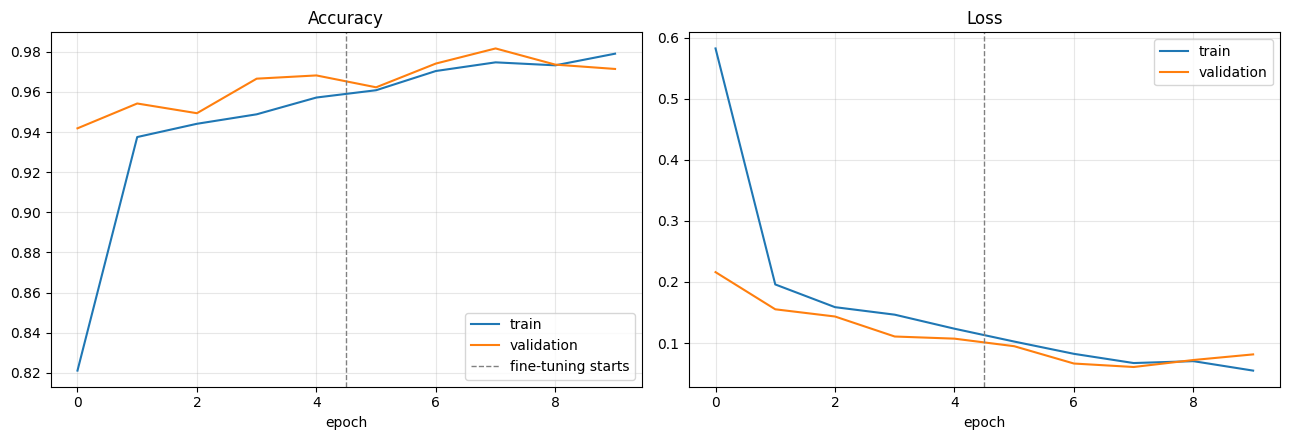

In [15]:
def plot_history(hist1, hist2):
    acc     = hist1.history["accuracy"]     + hist2.history["accuracy"]
    val_acc = hist1.history["val_accuracy"] + hist2.history["val_accuracy"]
    loss    = hist1.history["loss"]         + hist2.history["loss"]
    val_loss= hist1.history["val_loss"]     + hist2.history["val_loss"]
    split   = len(hist1.history["accuracy"])

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(acc, label="train")
    axes[0].plot(val_acc, label="validation")
    axes[0].axvline(split - 0.5, color="grey", ls="--", lw=1, label="fine-tuning starts")
    axes[0].set_title("Accuracy"); axes[0].set_xlabel("epoch")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(loss, label="train")
    axes[1].plot(val_loss, label="validation")
    axes[1].axvline(split - 0.5, color="grey", ls="--", lw=1)
    axes[1].set_title("Loss"); axes[1].set_xlabel("epoch")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=150)
    plt.show()


if RUN_MODE == "train":
    plot_history(hist1, hist2)

## 7. Evaluation

Accuracy alone is not enough for the report — the per-class report exposes which diseases
the model confuses, and the confusion matrix makes that visible.

Validation accuracy : 0.9817
Validation loss     : 0.0608

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9764    0.9841    0.9802       126
                                 Apple___Black_rot     0.9925    1.0000    0.9962       132
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        55
                                   Apple___healthy     1.0000    0.9939    0.9970       329
                               Blueberry___healthy     0.9966    1.0000    0.9983       295
          Cherry_(including_sour)___Powdery_mildew     0.9957    0.9914    0.9935       232
                 Cherry_(including_sour)___healthy     0.9940    0.9880    0.9910       167
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8932    0.8519    0.8720       108
                       Corn_(maize)___Common_rust_     0.9955    1.0000    0.9977       219
               Corn_

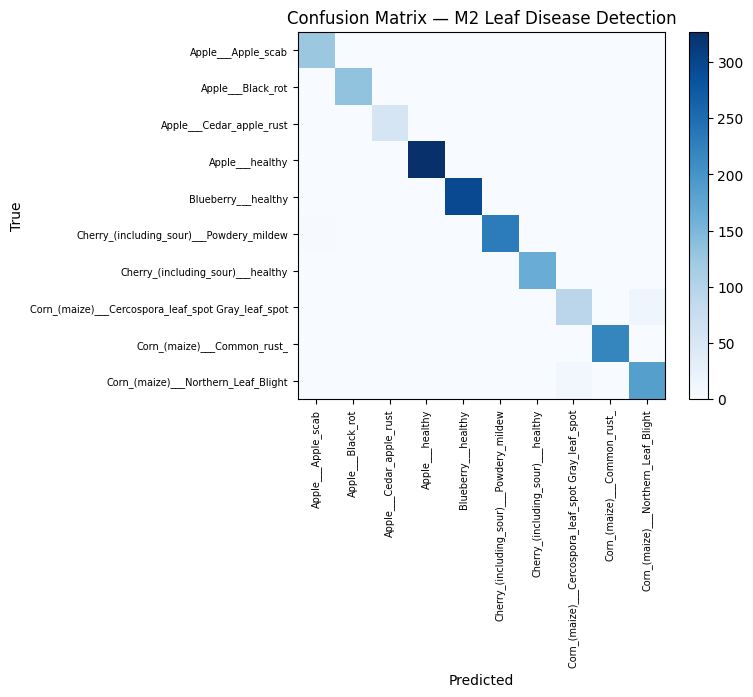

In [16]:
def evaluate(model, val_ds, class_names):
    from sklearn.metrics import classification_report, confusion_matrix

    loss, acc = model.evaluate(val_ds, verbose=0)
    print(f"Validation accuracy : {acc:.4f}")
    print(f"Validation loss     : {loss:.4f}\n")

    y_true, y_pred = [], []
    for images, labels in val_ds:
        probs = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(probs, axis=1))

    y_true, y_pred = np.array(y_true), np.array(y_pred)

    report = classification_report(
        y_true, y_pred, target_names=class_names, digits=4, zero_division=0
    )
    print(report)

    with open(os.path.join(OUTPUT_DIR, "classification_report.txt"), "w") as f:
        f.write(f"Validation accuracy: {acc:.4f}\nValidation loss: {loss:.4f}\n\n{report}")

    cm_matrix = confusion_matrix(y_true, y_pred)
    size = max(8, min(20, len(class_names) * 0.5))
    plt.figure(figsize=(size, size * 0.85))
    plt.imshow(cm_matrix, interpolation="nearest", cmap="Blues")
    plt.title("Confusion Matrix — M2 Leaf Disease Detection")
    plt.colorbar()
    ticks = np.arange(len(class_names))
    plt.xticks(ticks, class_names, rotation=90, fontsize=7)
    plt.yticks(ticks, class_names, fontsize=7)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
    plt.show()

    return acc


if RUN_MODE == "train":
    val_accuracy = evaluate(model, val_ds, class_names)

## 8. Grad-CAM — explaining the prediction

**The idea.** Take the gradient of the predicted class score with respect to the last
convolutional feature map. Channels with large gradients mattered most for that class, so
averaging each channel's gradient gives an importance weight. A weighted sum of the feature
maps, keeping only the positive part, shows *where* the evidence for that class lives.

This is what turns the module from a black box into an explainable one — and it is the
component the panel will ask about.

In [17]:
def compute_gradcam(gradcam_model, img_array, class_index=None):
    """
    Returns (heatmap in [0,1], explained class index, full probability vector).
    img_array: (1, H, W, 3) raw pixel values 0-255.
    """
    img_tensor = tf.convert_to_tensor(img_array, dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(img_tensor)
        feature_map, predictions = gradcam_model(img_tensor, training=False)
        if class_index is None:
            class_index = int(tf.argmax(predictions[0]))
        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, feature_map)      # d(score)/d(features)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))      # one weight per channel

    feature_map = feature_map[0]
    heatmap = tf.reduce_sum(feature_map * weights, axis=-1)

    heatmap = tf.maximum(heatmap, 0)                     # keep evidence FOR the class
    max_val = tf.reduce_max(heatmap)
    heatmap = heatmap / max_val if max_val > 0 else heatmap

    return heatmap.numpy(), class_index, predictions[0].numpy()


def overlay_heatmap(original_img, heatmap, alpha=0.45):
    """Resize the heatmap to the image, colour it, and blend it over the leaf photo."""
    heatmap_img = Image.fromarray(np.uint8(255 * heatmap)).resize(
        original_img.size, resample=Image.BILINEAR
    )
    heatmap_arr = np.array(heatmap_img) / 255.0

    # matplotlib >= 3.9 removed cm.get_cmap
    try:
        colormap = matplotlib.colormaps["jet"]
    except AttributeError:
        colormap = cm.get_cmap("jet")

    colored = np.uint8(colormap(heatmap_arr)[:, :, :3] * 255)
    base = np.array(original_img.convert("RGB")).astype(float)
    blended = (1 - alpha) * base + alpha * colored.astype(float)

    return Image.fromarray(np.uint8(np.clip(blended, 0, 255)))


def severity_from_heatmap(heatmap, threshold=0.5):
    """
    Indicative severity proxy: fraction of the attended area strongly activated.
    NOTE: this is a heuristic signal, not a calibrated agronomic measurement.
    Describe it as such in the report.
    """
    fraction = float(np.mean(heatmap >= threshold))
    label = "Low" if fraction < 0.10 else ("Moderate" if fraction < 0.25 else "High")
    return label, fraction

### 8.1 Visual check on validation images

Confirm the heatmaps land on the lesions rather than the background. If they highlight
background consistently, the model is exploiting a dataset artefact — worth reporting.

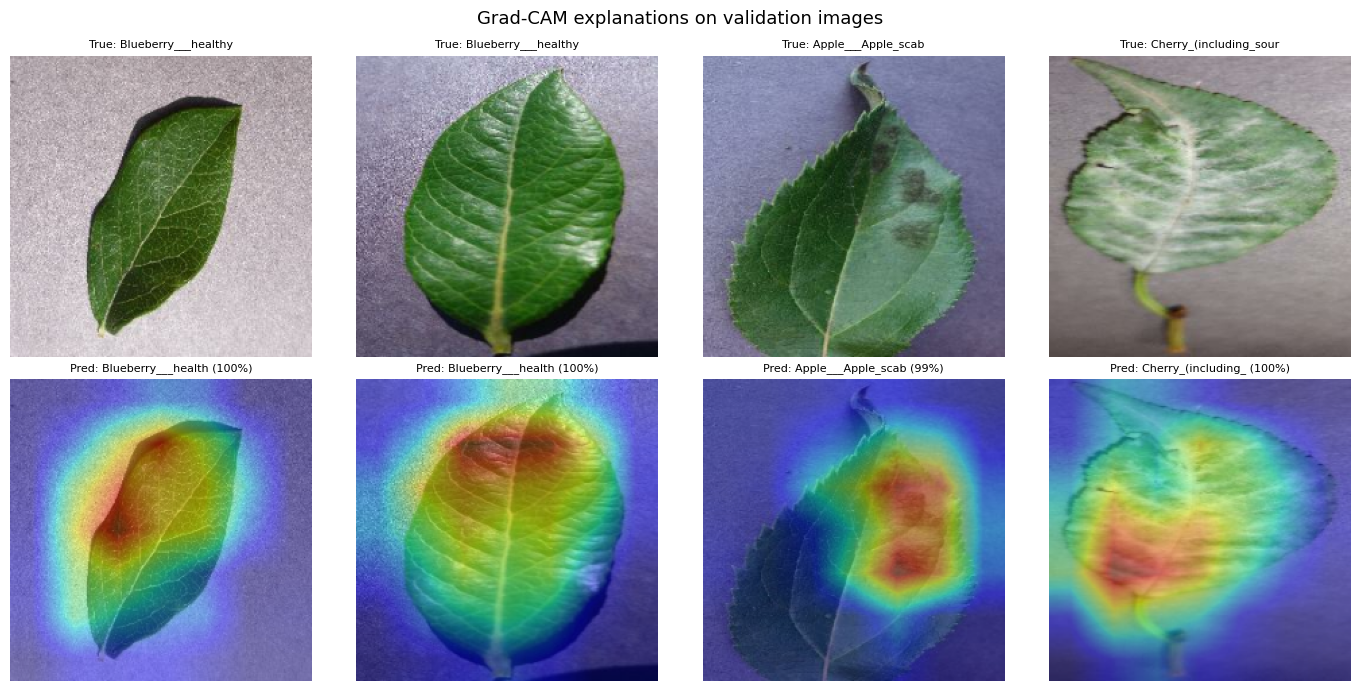

In [18]:
if RUN_MODE == "train":
    plt.figure(figsize=(14, 7))
    shown = 0
    for images, labels in val_ds.take(1):
        for i in range(min(4, images.shape[0])):
            arr = np.expand_dims(images[i].numpy(), axis=0)
            heatmap, idx, probs = compute_gradcam(gradcam_model, arr)

            pil = Image.fromarray(images[i].numpy().astype("uint8"))
            overlay = overlay_heatmap(pil, heatmap)

            plt.subplot(2, 4, shown + 1)
            plt.imshow(pil); plt.axis("off")
            plt.title(f"True: {class_names[labels[i]][:22]}", fontsize=8)

            plt.subplot(2, 4, shown + 5)
            plt.imshow(overlay); plt.axis("off")
            plt.title(f"Pred: {class_names[idx][:18]} ({probs[idx]*100:.0f}%)", fontsize=8)
            shown += 1

    plt.suptitle("Grad-CAM explanations on validation images", fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "gradcam_examples.png"), dpi=150)
    plt.show()

## 9. Load saved model (only when `RUN_MODE = "app"`)

Skips training entirely and restores the weights saved earlier.

In [19]:
if RUN_MODE == "app":
    if not (os.path.exists(WEIGHTS_PATH) and os.path.exists(CLASSES_PATH)):
        raise FileNotFoundError("Saved model not found — run once with RUN_MODE = 'train' first.")

    with open(CLASSES_PATH) as f:
        class_names = json.load(f)

    model, gradcam_model, backbone = build_model(len(class_names))
    model.load_weights(WEIGHTS_PATH)
    print(f"Weights restored from {WEIGHTS_PATH} ({len(class_names)} classes)")

## 10. Gradio application

Running this cell prints a public **`.gradio.live`** URL. Paste that URL into the HTML hub
as an `<iframe>` — this is the same integration pattern used across all four modules.

**Important:** the link stays alive only while this cell is running, so launch it shortly
before the demonstration rather than days ahead.

In [20]:
def prettify(class_name):
    """'Tomato___Late_blight' -> 'Tomato - Late blight'"""
    return " ".join(class_name.replace("___", " - ").replace("_", " ").split())


def predict(image):
    if image is None:
        return None, {}, "Please upload a leaf image."

    pil = Image.fromarray(image).convert("RGB")
    resized = pil.resize((IMG_SIZE, IMG_SIZE))
    arr = np.expand_dims(np.array(resized).astype("float32"), axis=0)

    heatmap, idx, probs = compute_gradcam(gradcam_model, arr)

    overlay = overlay_heatmap(pil, heatmap)
    severity, fraction = severity_from_heatmap(heatmap)

    top_k = min(5, len(class_names))
    order = np.argsort(probs)[::-1][:top_k]
    confidences = {prettify(class_names[i]): float(probs[i]) for i in order}

    predicted = prettify(class_names[idx])
    is_healthy = "healthy" in class_names[idx].lower()

    summary = f"### {predicted}\n\n**Confidence:** {probs[idx] * 100:.2f}%\n\n"
    if is_healthy:
        summary += "The model finds no disease symptoms in this leaf.\n\n"
    else:
        summary += (
            f"**Indicative severity:** {severity} "
            f"({fraction * 100:.1f}% of the leaf strongly activated)\n\n"
            "The highlighted region shows where the model detected symptoms. "
            "Confirm with an agricultural extension officer before treatment.\n\n"
        )
    summary += "*The heatmap shows the areas that most influenced this prediction (Grad-CAM).*"

    return overlay, confidences, summary

In [21]:
import gradio as gr

with gr.Blocks(title="M2 - Leaf Disease Detection") as demo:
    gr.Markdown(
        "# Leaf Disease Detection with Grad-CAM\n"
        "**Smart Crop Advisory System** &nbsp;|&nbsp; Module M2 &nbsp;|&nbsp; "
        "SIH25010 &nbsp;|&nbsp; SIT Pune, Dept. of AI & ML\n\n"
        "Upload a leaf photograph. The model predicts the disease class and highlights "
        "the region that drove its decision."
    )

    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="numpy", label="Leaf image")
            btn = gr.Button("Analyse", variant="primary")
        with gr.Column():
            out_img = gr.Image(label="Grad-CAM explanation")
            out_lbl = gr.Label(label="Top predictions", num_top_classes=5)

    out_txt = gr.Markdown()

    btn.click(predict, inputs=inp, outputs=[out_img, out_lbl, out_txt])
    inp.upload(predict, inputs=inp, outputs=[out_img, out_lbl, out_txt])

    gr.Markdown(
        "---\n*Research prototype trained on a public dataset. "
        "Not a substitute for professional agronomic advice.*"
    )

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7481113079b624c72d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
